# AirGuard India — Phase 1: Problem Statement and Dataset

**AD23532 · Principles of Data Science**
Rajalakshmi Engineering College (Autonomous, affiliated to Anna University, Chennai)

| | |
| --- | --- |
| Phase | 1 of 3 — Review 1 |
| Rubric rows addressed | Problem statement; dataset selection and quality; project charter; methodology; planning |
| Degree and branch | B.Tech. Artificial Intelligence and Data Science |
| Regulation / Year / Semester | 2023 / 2026-27 (ODD) / V |
| Team | 260586 (Nishanth Rajendran), 260598 (<NAME>), 260600 (<NAME>) |
| Repository | https://github.com/nishaids/airguard-india |

---

> **How to read this notebook.** It contains orchestration and narrative only.
> Every piece of analysis logic lives in the `src/` package and is imported
> here, so nothing shown below can drift away from the code that produced the
> committed results. Every number displayed is read from `results/*.json`, which
> the pipeline writes; none is typed by hand.


In [1]:
import sys, json
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, Markdown, display

from src import config

config.set_global_seed()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

RESULTS = config.RESULTS_DIR
FIGURES = config.FIGURES_DIR

def load(name: str) -> dict:
    """Load a results artefact by file name."""
    path = RESULTS / name
    return json.loads(path.read_text(encoding="utf-8")) if path.exists() else {}

def show(filename: str, caption: str = "") -> None:
    """Display a pipeline-generated figure with its caption."""
    path = FIGURES / filename
    if path.exists():
        display(Image(filename=str(path), width=900))
        if caption:
            display(Markdown(f"*{caption}*"))
    else:
        display(Markdown(f"> Figure `{filename}` not found. Run `python run_all.py`."))

print(f"Project root: {ROOT}")
print(f"Global seed:  {config.RANDOM_SEED}")


Project root: D:\PODS Project\airguard-india
Global seed:  42


## 1. The problem

India's air quality index is accurate but has two structural limitations as a personal health signal: it is a single population-average number reported identically to every person in a city, and it is retrospective. This project forecasts the next day and resolves the advisory by vulnerability cohort, while guaranteeing that it is never less protective than the official index.

The full problem statement, the six research objectives with their measurable success criteria, and the project charter are in `reports/Review1_Problem_and_Dataset.docx`, generated from the same artefacts this notebook reads.

## 2. Acquisition and provenance

The dataset is acquired programmatically. The acquisition module emits an audit trail a reviewer can independently re-verify: SHA-256 checksums for every file, the licence string read from the live dataset page at download time, and a full column-level schema profile.

In [2]:
provenance = json.loads((config.RAW_DIR / "PROVENANCE.json").read_text(encoding="utf-8"))
dataset, licence = provenance["dataset"], provenance["license"]
primary = provenance["primary_file"]

display(Markdown(f"""
| Field | Value |
| --- | --- |
| Title (scraped from the source page) | {dataset["title_scraped"]} |
| Upstream producer | {provenance["upstream_source"]["organisation"]} |
| Mirror | {dataset["kaggle_url"]} |
| **Licence as displayed** | **{licence["string_as_displayed_on_kaggle"]}** |
| Verified live at download | {licence["verified_live"]} |
| Retrieved (UTC) | {provenance["downloaded_at_utc"]} |
| Rows | {primary["rows"]:,} |
| Columns | {primary["columns"]} |
| Cities | {primary["n_cities"]} |
| Coverage | {primary["date_min"]} to {primary["date_max"]} |
"""))


| Field | Value |
| --- | --- |
| Title (scraped from the source page) | Air Quality Data in India (2015 - 2020) |
| Upstream producer | Central Pollution Control Board (CPCB), Ministry of Environment, Forest and Climate Change, Government of India |
| Mirror | https://www.kaggle.com/datasets/rohanrao/air-quality-data-in-india |
| **Licence as displayed** | **CC0: Public Domain** |
| Verified live at download | True |
| Retrieved (UTC) | 2026-09-28T17:29:24Z |
| Rows | 29,531 |
| Columns | 16 |
| Cities | 26 |
| Coverage | 2015-01-01 to 2020-07-01 |


The licence recorded above is the string the source page actually displayed, not an assumption inherited from the upstream agency's usual terms. The compiled dataset and its upstream source are separately licensed artefacts, and conflating them would misstate the terms under which this work redistributes anything.

In [3]:
rows = [
    {
        "File": f["filename"],
        "Size (MB)": f["size_mb"],
        "Rows": f["rows"],
        "Columns": f["columns"],
        "In data/raw/": f["retained_in_data_raw"],
        "SHA-256 (first 16)": f["sha256"][:16] + "...",
    }
    for f in provenance["files"] if f.get("present")
]
display(Markdown("### Files acquired, with checksums"))
display(pd.DataFrame(rows))

### Files acquired, with checksums

,File,Size (MB),Rows,Columns,In data/raw/,SHA-256 (first 16)
0,city_day.csv,2.574,29531,16,True,0d84b21c3e4878bb...
1,city_hour.csv,65.649,707875,16,True,fae474062ec6b10a...
2,station_day.csv,8.634,108035,16,True,f07787eb4c36c53b...
3,station_hour.csv,219.675,2589083,16,False,26a423c66fe97630...
4,stations.csv,0.014,230,5,True,ce2b7081c3e3c891...


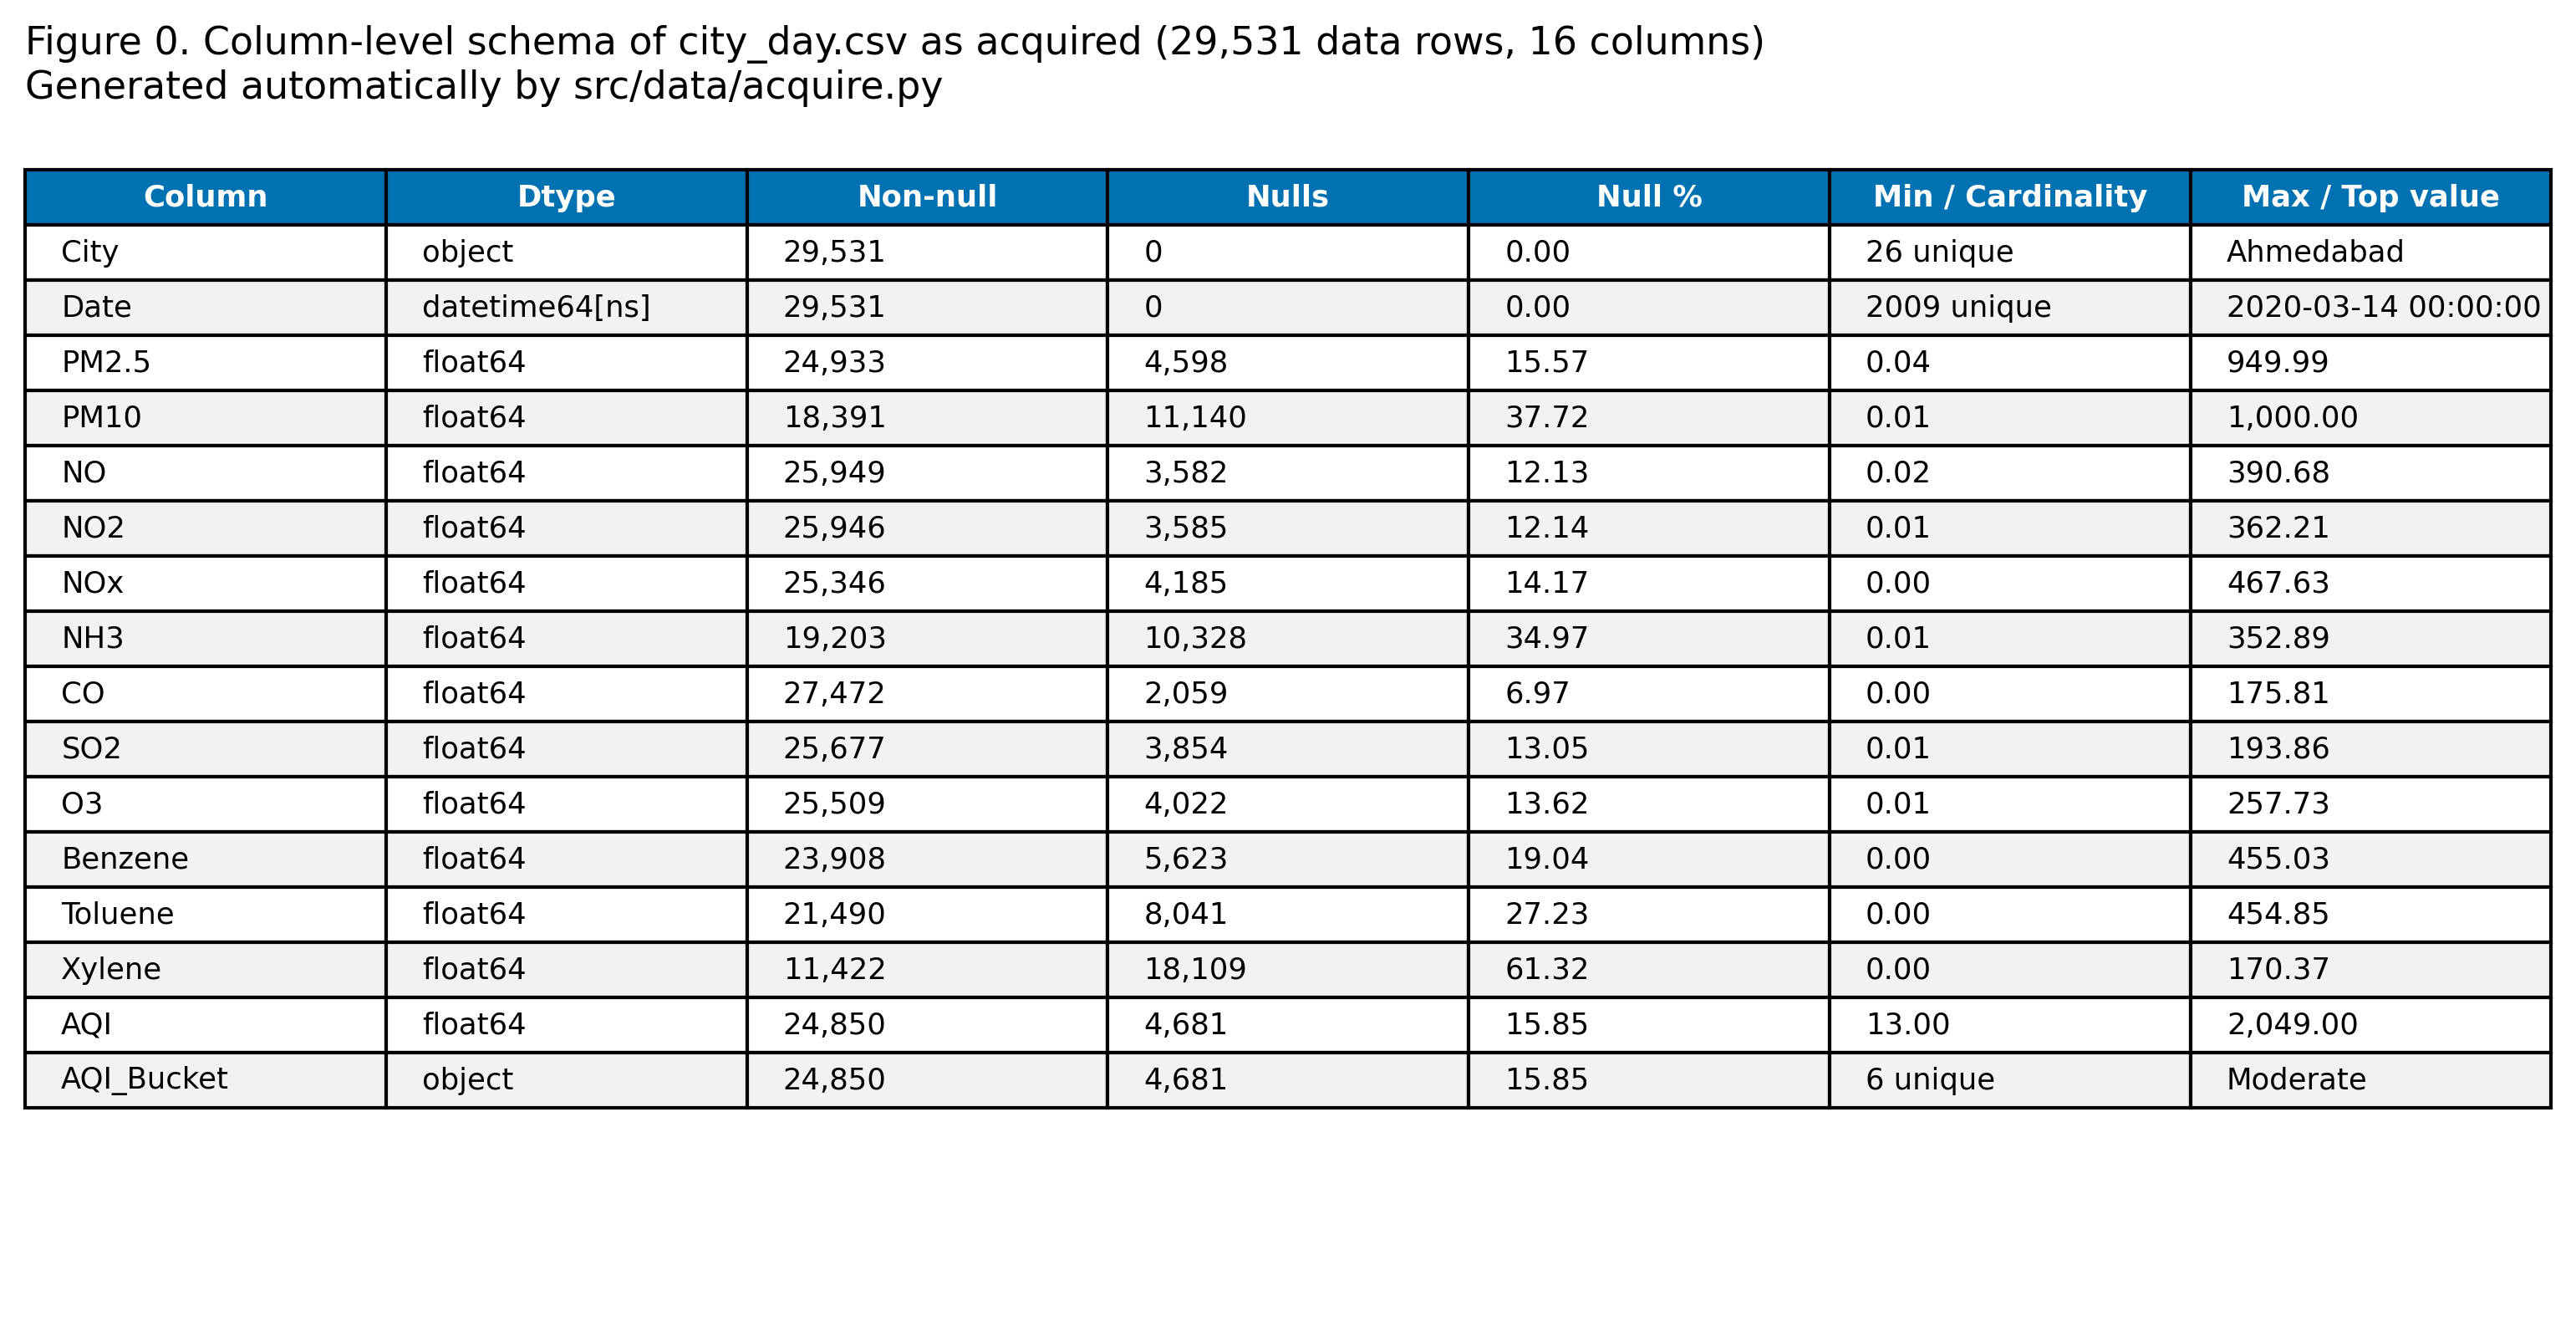

*Figure 1. Column-level schema of city_day.csv rendered directly from the acquired file. This is documentary evidence that the schema was read rather than transcribed.*

In [4]:
show("00_dataset_proof_schema.png",
     "Figure 1. Column-level schema of city_day.csv rendered directly from the acquired file. This is documentary evidence that the schema was read rather than transcribed.")

## 3. Initial quality assessment

The assessment runs in full before any cleaning decision is taken, so that each decision can be justified by a measurement rather than by an expectation.

In [5]:
quality = load("data_quality_report.json")
invalid, duplicates = quality["invalid_values"], quality["duplicates"]
consistency = invalid["bucket_consistency"]

display(Markdown(f"""
| Check | Result |
| --- | --- |
| Fully duplicated rows | {duplicates["fully_duplicated_rows"]} |
| Duplicate (City, Date) keys | {duplicates["duplicated_city_date_keys"]} |
| Missing calendar days | {invalid["dates"]["total_missing_calendar_days"]} |
| Columns failing a unit check | {quality["unit_sanity"]["n_flagged"]} |
| City naming | {quality["city_naming"]["verdict"]} |
| AQI above the CPCB 0-500 scale | {invalid["aqi"]["aqi_above_scale_max_500"]} ({invalid['aqi']['aqi_above_scale_max_500_pct']}%) |
| AQI_Bucket reproducible from AQI | {consistency["agreement_pct"]}% ({consistency['mismatches']} mismatches) |
"""))


| Check | Result |
| --- | --- |
| Fully duplicated rows | 0 |
| Duplicate (City, Date) keys | 0 |
| Missing calendar days | 0 |
| Columns failing a unit check | 0 |
| City naming | consistent |
| AQI above the CPCB 0-500 scale | 543 (2.185%) |
| AQI_Bucket reproducible from AQI | 100.0% (0 mismatches) |


The final row is the important one. The band is reproducible from the AQI by the published cut points alone, which is verified here rather than assumed. That fact establishes the label-leakage hazard that the forecasting formulation dissolves, and which phase 3 measures directly.

In [6]:
balance = quality["class_balance"]
display(Markdown("### AQI band distribution"))
display(pd.DataFrame(balance["distribution"]))
display(Markdown(f"**Imbalance ratio:** {balance['imbalance_ratio_max_over_min']}\n\n"
                 f"{balance['implication']}"))

### AQI band distribution

,bucket,count,pct
0,Good,1341,5.396
1,Satisfactory,8224,33.095
2,Moderate,8829,35.529
3,Poor,2781,11.191
4,Very Poor,2337,9.404
5,Severe,1338,5.384


**Imbalance ratio:** 6.6

The bucket distribution is markedly uneven, so overall accuracy is not an adequate summary: a model that never predicts the rarest class can still score well. Macro-averaged F1 is therefore declared the primary classification metric, with per-class F1 reported alongside it.

## 4. City selection

Two gates, both fixed before any model was fitted. No city is dropped silently: every exclusion appears below with its completeness figure and its reason.

In [7]:
retention = quality["city_retention"]
table = pd.DataFrame(retention["decisions"])[
    ["city", "labelled_days", "aqi_completeness", "retained", "reason"]
]
display(Markdown(f"**{retention['n_retained']} of "
                 f"{retention['n_retained'] + retention['n_excluded']} cities retained.**"))
display(table)
display(Markdown(f"*{retention['threshold_justification']}*"))

**12 of 26 cities retained.**

,city,labelled_days,aqi_completeness,retained,reason
0,Ahmedabad,1334,0.6640,False,Excluded: completeness 66.4% < 80%.
1,Aizawl,111,0.9823,False,Excluded: only 111 labelled days < 730.
2,Amaravati,841,0.8843,True,AQI completeness 88.4% >= 80% and 841 labelled...
3,Amritsar,1126,0.9222,True,"AQI completeness 92.2% >= 80% and 1,126 labell..."
4,Bengaluru,1910,0.9507,True,"AQI completeness 95.1% >= 80% and 1,910 labell..."
5,Bhopal,278,0.9619,False,Excluded: only 278 labelled days < 730.
6,Brajrajnagar,713,0.7601,False,Excluded: completeness 76.0% < 80%; only 713 l...
7,Chandigarh,299,0.9836,False,Excluded: only 299 labelled days < 730.
8,Chennai,1884,0.9378,True,"AQI completeness 93.8% >= 80% and 1,884 labell..."
9,Coimbatore,344,0.8912,False,Excluded: only 344 labelled days < 730.


*Two independent gates are applied. The completeness gate (80% of the calendar days in a city's own observation span must carry a labelled AQI) ensures that per-city lag and rolling features are computed over a near-contiguous series rather than across long gaps, since a lag of one row is only a lag of one day when the series is dense. The volume gate (at least 730 labelled days, i.e. two years) ensures each retained city contributes at least two full annual cycles, so that seasonal structure is estimable and a time-ordered split leaves a usable test period. Both thresholds were fixed before any model was fitted and are not tuned against model performance.*

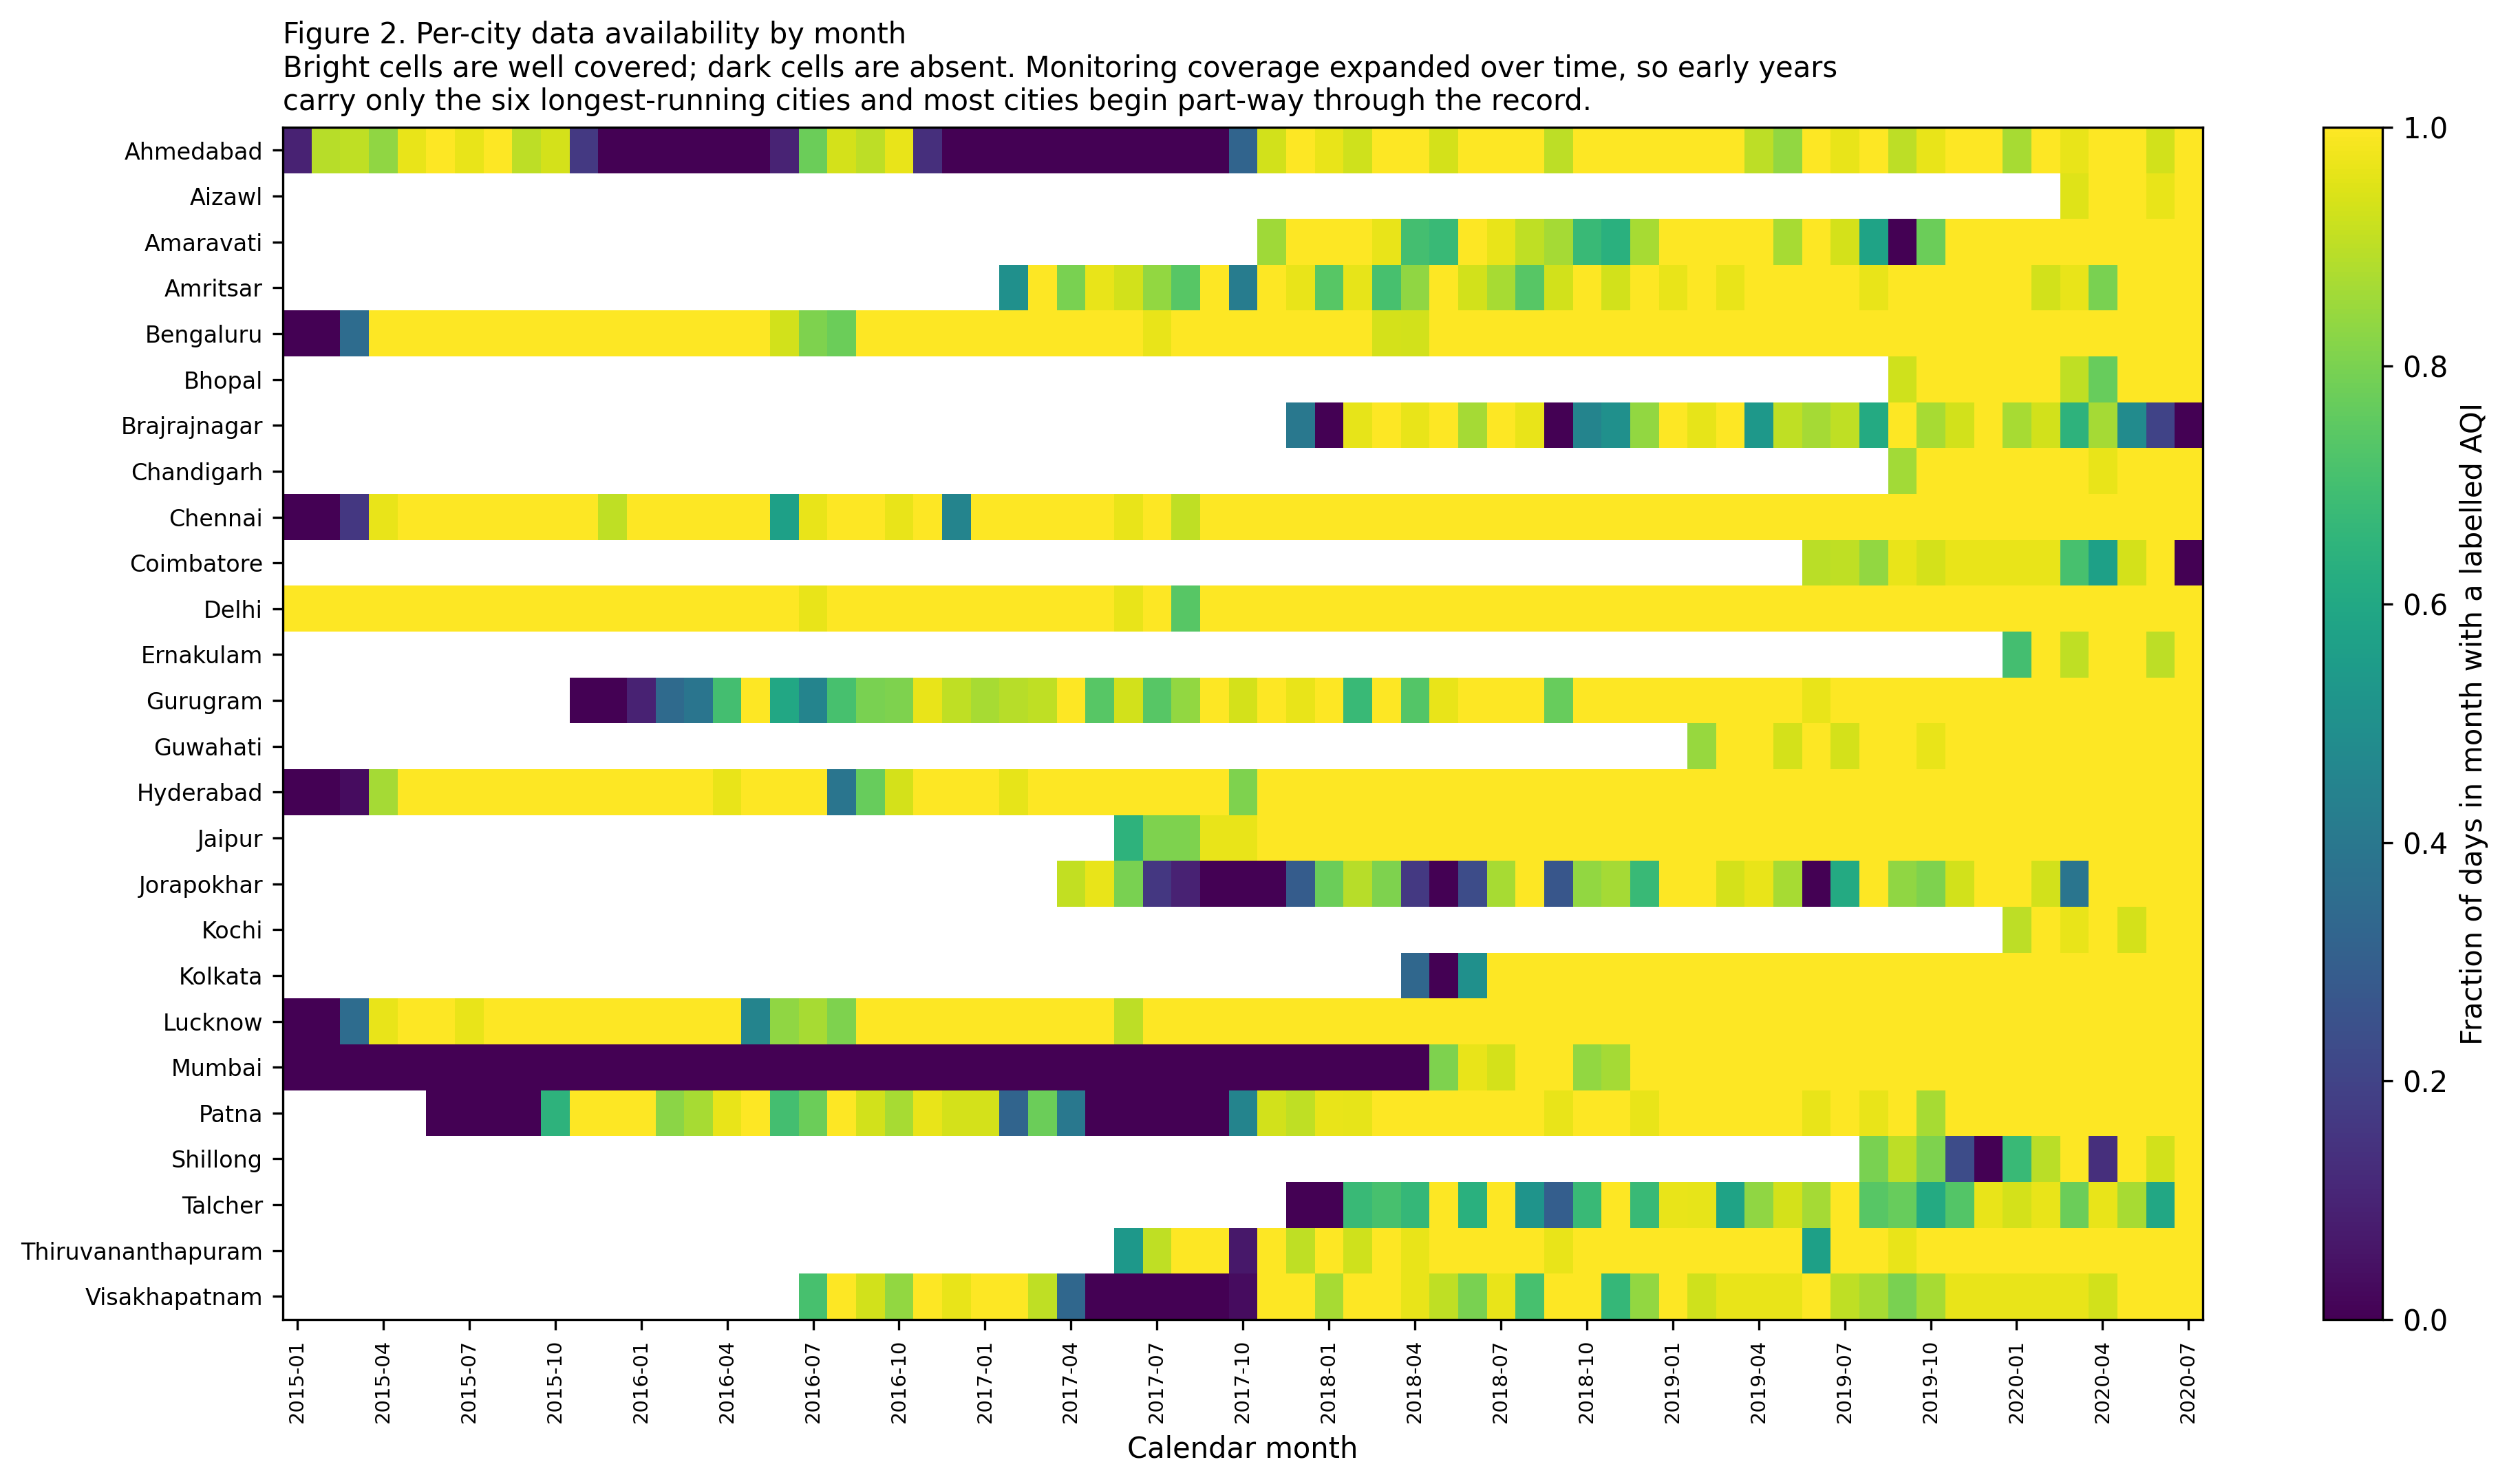

*Figure 2. Per-city availability of a labelled AQI by month. Coverage expanded over the record, which is the structural reason a national trend across the full span cannot be claimed from these data.*

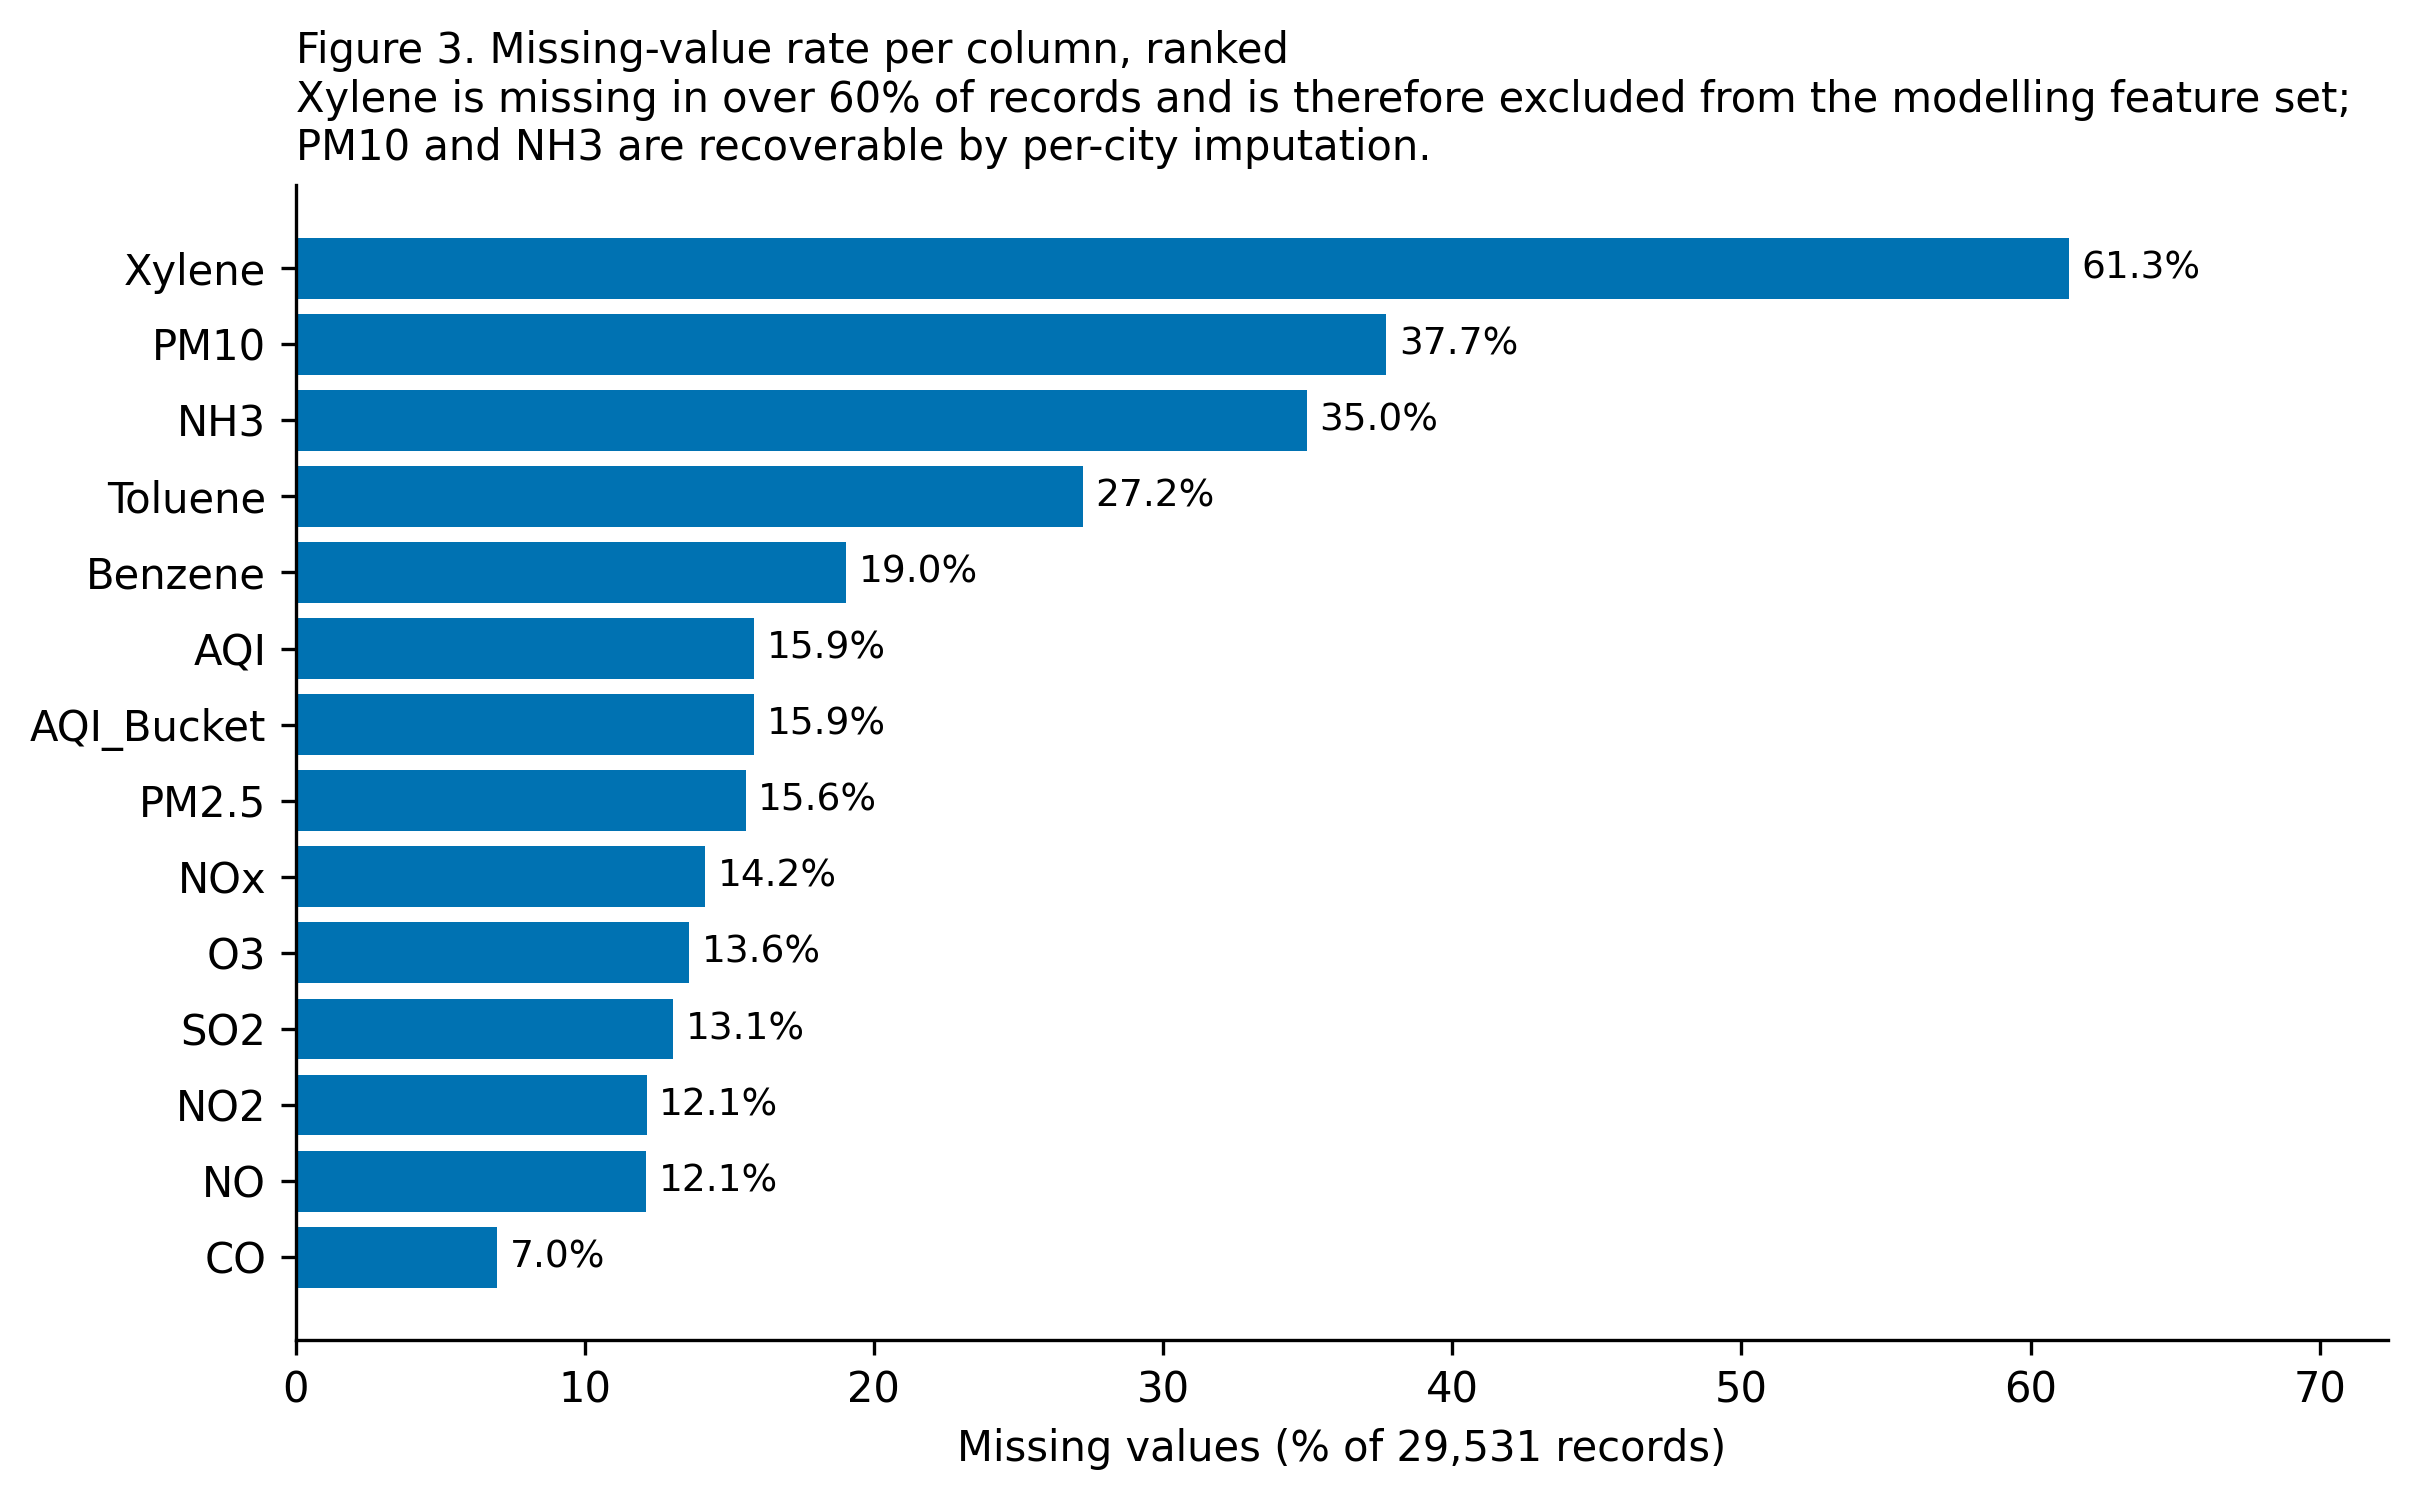

*Figure 3. Missing-value rate per column.*

In [8]:
show("02_city_availability_heatmap.png",
     "Figure 2. Per-city availability of a labelled AQI by month. Coverage expanded over the record, which is the structural reason a national trend across the full span cannot be claimed from these data.")
show("03_null_percentage_bar.png", "Figure 3. Missing-value rate per column.")

## 5. Methodology

The pipeline below is the design the remaining two phases execute. The leakage controls in the lower band apply at every stage rather than at a single checkpoint.

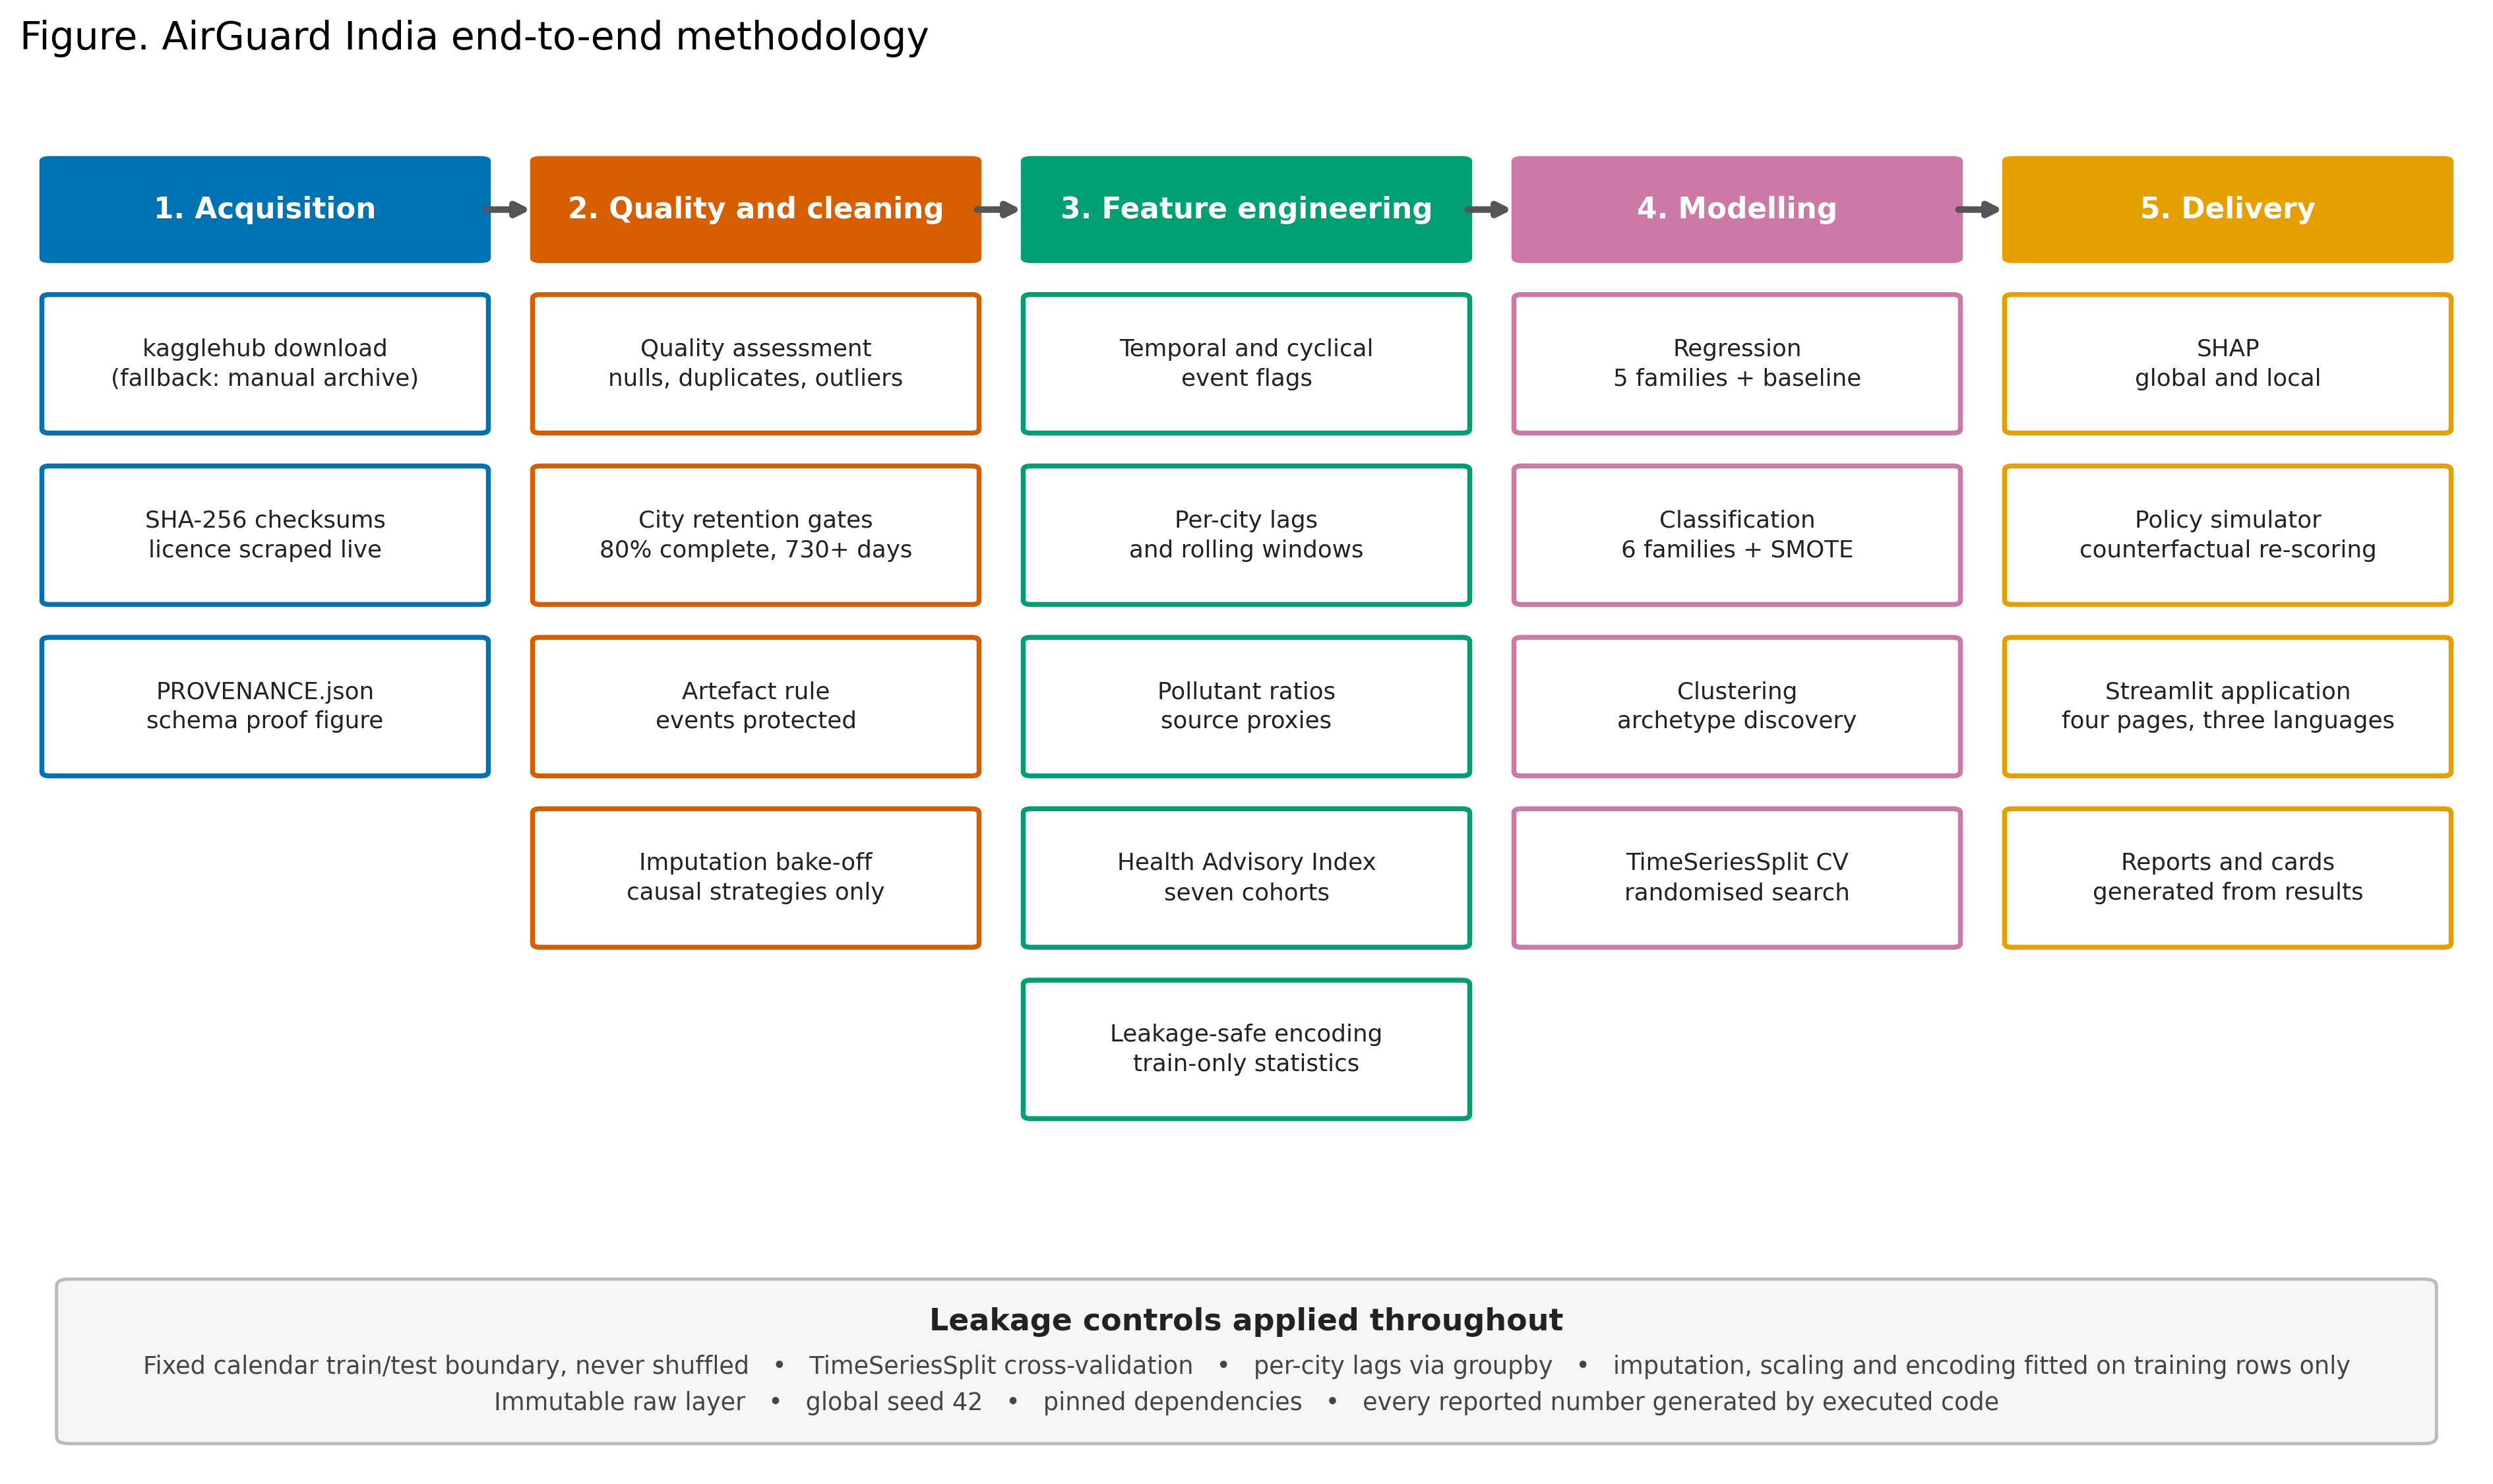

*Figure 4. End-to-end methodology.*

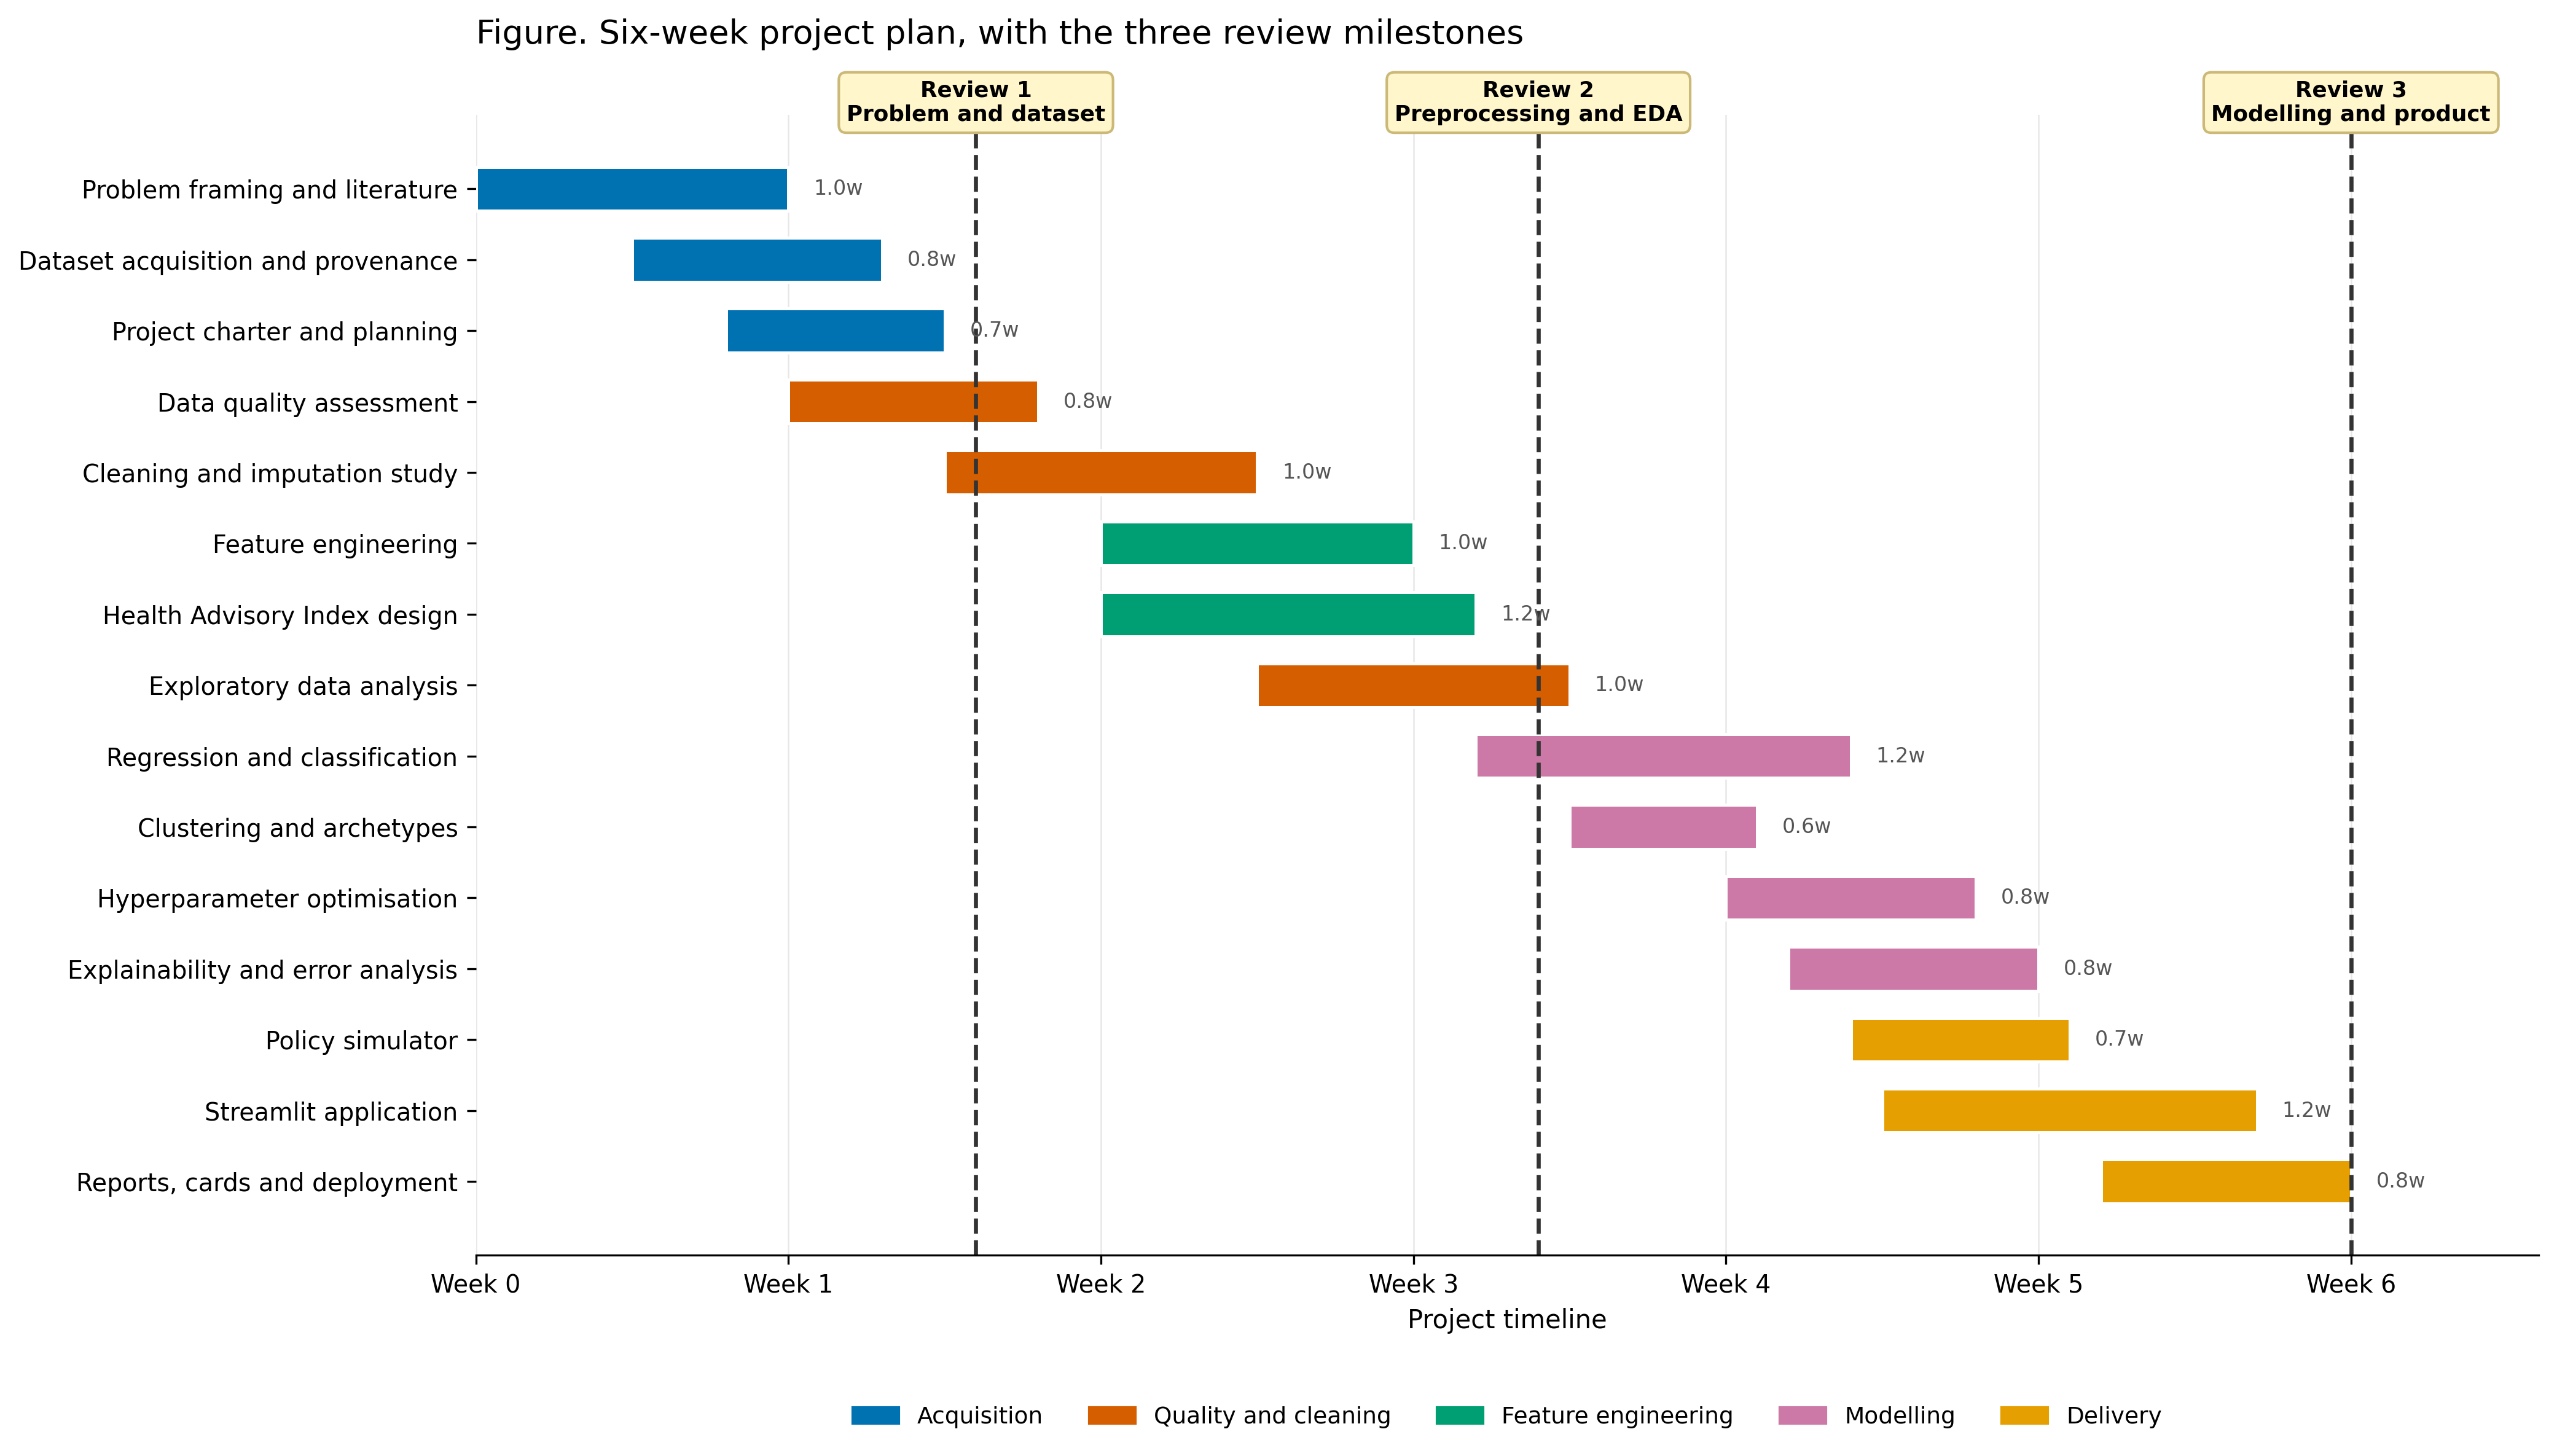

*Figure 5. Six-week project plan with the three review milestones.*

In [9]:
show("39_pipeline_diagram.png", "Figure 4. End-to-end methodology.")
show("40_project_gantt.png", "Figure 5. Six-week project plan with the three review milestones.")

## 6. Phase 1 outcome

* Dataset acquired, with a machine-verified provenance record.
* Quality assessed; the label-leakage hazard identified and verified.
* City selection gates applied with every decision recorded.
* Methodology, charter and plan fixed.

Phase 2 cleans the record, engineers the features and builds the Health Advisory Index.